# Activity7.05: Linear regression for animal attribute relations

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 02

Data: `anage_data.csv`. 

## Activity7.05 — 01. Read the AnAge data

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
sns.set_theme()
mydata = pd.read_csv(DATA_DIR / 'anage_data.csv', index_col=0)
mass = 'Body mass (g)'
longevity = 'Maximum longevity (yrs)'
print('Input records:', len(mydata))
display(mydata[['Common name', 'Class', mass, longevity]].head())

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Input records: 4218


,Common name,Class,Body mass (g),Maximum longevity (yrs)
0,Daphnia,Branchiopoda,NaN,0.19
1,Fruit fly,Insecta,NaN,0.30
2,Honey bee,Insecta,NaN,8.00
3,Cardiocondyla obscurior,Insecta,NaN,0.50
4,Black garden ant,Insecta,NaN,28.00


## Activity7.05 — 02. Filter complete Mammalia records below 200000 g

In [2]:
data = mydata[mydata['Class'].eq('Mammalia')].copy()
data = data[np.isfinite(data[longevity]) & np.isfinite(data[mass])
            & (data[mass] < 200000)]
print('Filtered records:', len(data))
print('Classes:', data['Class'].unique().tolist())
print('Maximum body mass (g):', data[mass].max())
print('Missing values:', data[[mass, longevity]].isna().sum().to_dict())
display(data[[mass, longevity]].describe().round(2))

Filtered records: 345
Classes: ['Mammalia']
Maximum body mass (g): 196500.0
Missing values: {'Body mass (g)': 0, 'Maximum longevity (yrs)': 0}


,Body mass (g),Maximum longevity (yrs)
count,345.00,345.00
mean,7936.86,14.63
std,25247.67,11.18
min,2.40,2.20
25%,53.00,6.30
50%,344.00,12.00
75%,2846.60,20.60
max,196500.00,122.50


## Activity7.05 — 03. Draw the regression plot

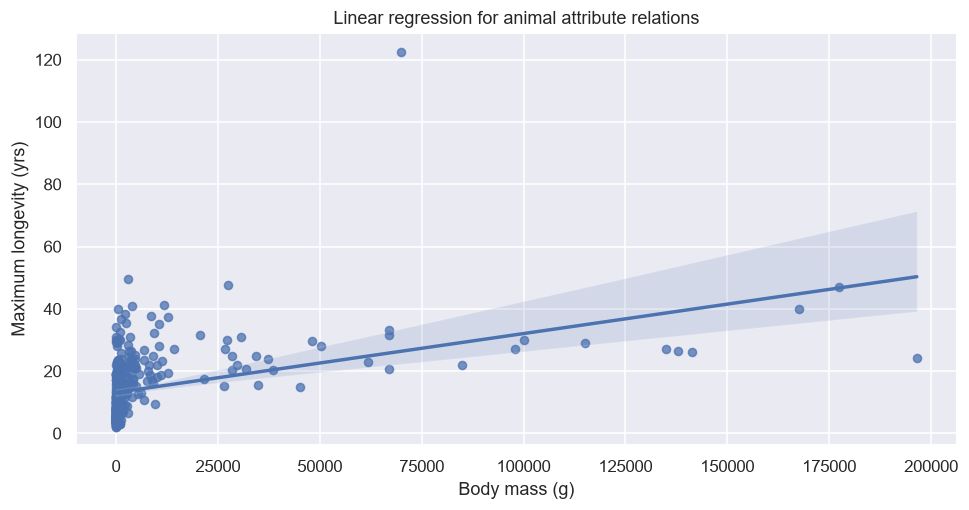

Pearson r: 0.427


In [3]:
plt.figure(figsize=(9, 4.8), dpi=110)
sns.regplot(data=data, x=mass, y=longevity, seed=643920,
            scatter_kws={'s': 28, 'alpha': 0.75})
plt.title('Linear regression for animal attribute relations')
plt.xlabel('Body mass (g)')
plt.ylabel('Maximum longevity (yrs)')
plt.tight_layout()
plt.show()
print('Pearson r:', round(data[[mass, longevity]].corr().iloc[0, 1], 3))

The fitted line rises, indicating a positive sample association, with substantial scatter and influential outliers. This observational cross-species relationship does not show that increasing body mass causes longer life.